# In-class project

A baseline Jupyter notebook for an in-class project for learning the materials at [github.com/ale66/learn-coding](https://github.com/ale66/learn-coding/).

Please do no edit this file: rather, make a copy, call it `a-.ipynb` then `git add`, `git commit` and `git push` it to [github.com/ale66/learn-coding-playground-2026-27](https://github.com/ale66/learn-coding-playground-2026-27/).


Do we have all required Python modules?

In [1]:
!pip install wget

zsh:1: command not found: pip


In [2]:
# Setup phase: not needed for Jupyter, uncomment as needed.

# MYWORKDIR = "C:\\Users\\ale\\Downloads\\_git\\learn-coding-playground-2026-27\\migration"

# import os
# os.chdir(MYWORKDIR)

Prepare the wget invisible browser, make it look like human using Firefox 

In [3]:

import os
import urllib.request

myopener = urllib.request.build_opener()

myopener.addheaders = [
    ("User-Agent", "Mozilla/5.0"),
    ("Referer", "https://data.spectator.co.uk/"),
    ("Verify", False)
]

urllib.request.install_opener(myopener)

Default setup, change as you see fit.

In [4]:
new_data_file = "data/small-boats.csv"

new_figure = "data/small-boats-replica.png"

In [5]:
import wget

# data of the "small boat crossings" chart on data.spectator.co.uk/migration
# these are not all-caps constants: we plan to do this for more than one file

url = "https://datawrapper.dwcdn.net/58WcU/22/dataset.csv"

os.makedirs("data", exist_ok=True)

if os.path.exists(new_data_file):
    os.remove(new_data_file)

fname = wget.download(url, out=new_data_file)

print(f"Data file from {url} saved as {new_data_file}")

# Open the file, import data

ModuleNotFoundError: No module named 'wget'

In [ ]:
import csv

# Check out the first 5 rows
R = 5

with open(new_data_file) as f:
    reader = csv.reader(f, delimiter="\t")

    for _ in range(R):
        print(next(reader))

# Data ingestion: read data and put it into your lists

['', 'Albanian', 'Total less Albanian']
['2018 Q1', '221', '2400']
['2018 Q2', '250', '2536']
['2018 Q3', '278', '3278']
['2018 Q4', '343', '4071']


Prepare the Python variable for transferring data (aka. Data ingestion).

In [ ]:
labels = []
albanians = []
others = []


In [ ]:

with open(new_data_file) as f:
    reader = csv.reader(f, delimiter="\t")

    # chuck the first row
    next(reader)
    
    for row in reader:
        labels.append(row[0])
        albanians.append(int(row[1]))
        others.append(int(row[2]))

# preview the data: the first R values
print('This is the data from file ', new_data_file)
print(labels[:R])
print(albanians[:R])
print(others[:R])


This is the data from file  data/small-boats.csv
['2018 Q1', '2018 Q2', '2018 Q3', '2018 Q4', '2019 Q1']
[221, 250, 278, 343, 256]
[2400, 2536, 3278, 4071, 3482]


### Visualisation: reproduce the original data display

In [ ]:
import matplotlib.pyplot as plt

# our main command: create a 8x5 inches black canvas
fig, ax = plt.subplots(figsize=(8, 5), facecolor="black")

# set the area between the axes
ax.set_facecolor("black")

plt.close(fig)

Select labels for the horizontal axis (the 'x')

To reproduce the plot, we will keep one label in 4, i.e., every year. 

Change this as you see fit.

In [ ]:

x = range(len(labels))

tick_pos = []
tick_names = []

for i in x:
    if i % 4 == 0:  # one label every two years
        tick_pos.append(i)
        tick_names.append(labels[i])

# check the work done
print("We'll use these tick positions and labels: ")
print(tick_pos)
print(tick_names)

We'll use these tick positions and labels: 
[0, 4, 8, 12, 16, 20, 24, 28]
['2018 Q1', '2019 Q1', '2020 Q1', '2021 Q1', '2022 Q1', '2023 Q1', '2024 Q1', '2025 Q1']


Prepare the x-axis visualisation

In [ ]:

ax.set_xticks(tick_pos)
ax.set_xticklabels(tick_names)

[Text(0, 0, '2018 Q1'),
 Text(4, 0, '2019 Q1'),
 Text(8, 0, '2020 Q1'),
 Text(12, 0, '2021 Q1'),
 Text(16, 0, '2022 Q1'),
 Text(20, 0, '2023 Q1'),
 Text(24, 0, '2024 Q1'),
 Text(28, 0, '2025 Q1')]

Prepare the y-axis visualisation

In [ ]:

# draw horizontal lines for values 0, 5000 etc.
ax.set_yticks([0, 5000, 10000, 15000, 20000])

# keep as it is: it prints values near the horizontal lines as 5,000, 10,000 (instead of 5000, 10000...)
ax.yaxis.set_major_formatter("{x:,.0f}")

# ok, draw a grid with horizontal white lines
ax.yaxis.grid(True, color="white")

# makes the lines pass below the actual values
ax.set_axisbelow(True)

# print the ticks in gray instead of the default black. Don't show the tick on the axis
ax.tick_params(colors="lightgray", length=0)

# show only the bottom of the grid, in white
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)

ax.spines["bottom"].set_color("white")



Write a description on top left corner of the data display.

The writing begins in position (0.03, 0.97), try changing as you see fit.

In [ ]:

fig.text(0.03, 0.97, "Irregular migrants", color="white", fontsize=22,
         fontfamily="serif", fontweight="bold", va="top")

fig.text(0.03, 0.88, "Numbers of irregular migrants detected each quarter",
         color="lightgray", fontsize=13, fontfamily="serif", va="top")



Text(0.03, 0.88, 'Numbers of irregular migrants detected each quarter')

Draw the data for Albanians.
Change ax.bar for a different visualisation style.

In [ ]:

ax.bar(x, albanians, width=0.65, color="tomato", label="Albanians")

# uncomment to also draw the data about all others
ax.bar(x, others, width=0.65, color="deepskyblue", label="Others", bottom=albanians)


<BarContainer object of 30 artists>

In [ ]:
ax.legend(loc="lower left", bbox_to_anchor=(-0.05, 1.0), ncol=2, frameon=False,
          labelcolor="white", fontsize=11, handlelength=1, handleheight=1)

Put the data display out.

Set the padding around the data display as a percentage.

Empty space at the top if for title/caption.

In [ ]:
# the traditional version does not work well in Jupyter
# plt.subplots_adjust(top=0.75, left=0.1, right=0.9, bottom=0.1)

# plt.savefig(new_figure)
# plt.show()


Functional version:

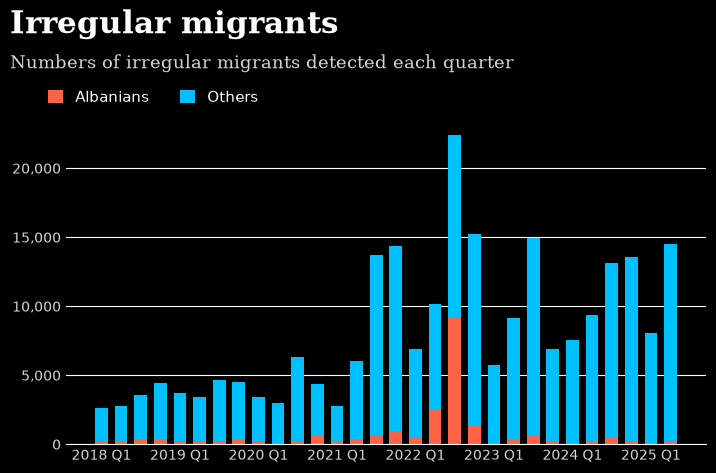

In [ ]:
fig.subplots_adjust(top=0.75, left=0.1, right=0.9, bottom=0.1)

fig.savefig(new_figure, facecolor="black")

display(fig)     # show the finished figure once